# Exercícios de programação: filtragem, CLAHE e segmentação

**Projeto:** Retina em Foco, IFPE Campus Palmares, Módulo 02.  
**Material utilizado:** repositório `pdib`, notebooks 03 e 04, e *Leitura Dirigida*, seções 4 e 5.  
**Autor da entrega:** [preencher]  
**Data da submissão:** [preencher]

## Objetivo

Construir e avaliar um pipeline clássico de processamento de retinografias:

1. localizar o campo de visão da retina, denominado FOV;
2. introduzir ruído conhecido e comparar filtros de suavização;
3. aplicar CLAHE na luminância L do espaço LAB;
4. identificar vasos retinianos com Frangi e com black-hat morfológico;
5. medir o contraste e, **quando existir máscara manual oficial**, avaliar a segmentação por Dice, IoU, sensibilidade e precisão.

A atividade é didática. Resultados de segmentação não são diagnósticos médicos.

## Como executar

**Dentro do repositório original:** coloque este arquivo na pasta `notebooks/`, instale as dependências de `requirements.txt` e abra-o no Jupyter ou no VS Code. É possível executar sem as imagens HRF, porque há uma retinografia de exemplo distribuída com `scikit-image`.

**Para avaliar com máscaras oficiais:** execute `python scripts/download_data.py` na raiz de `pdib` e reinicie o notebook. O manifesto `data/manifest.csv` sozinho não contém as imagens. O download precisa de conexão e pode ocupar cerca de 165 MB.

**Pacote de entrega independente:** se recebeu este notebook em um ZIP com `src/retina_pdi`, extraia o pacote, instale `requirements.txt`, abra `notebooks/` e execute as células. A amostra de `scikit-image` não possui máscara manual de vasos.

**Reprodutibilidade:** a geração de ruído usa uma semente numérica fixa. Todas as métricas são calculadas apenas dentro do FOV. Os números salvos no notebook mostram a execução de demonstração sem as máscaras HRF.

In [17]:
from pathlib import Path
import sys
import time
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from skimage import data as skdata
from IPython.display import display

# O notebook encontra o código de retina_pdi na raiz ou em uma pasta-pai.
cwd = Path.cwd().resolve()
candidatas = [cwd, *cwd.parents, cwd / "pdib-main", cwd.parent / "pdib-main"]
raiz = next((p for p in candidatas if (p / "src" / "retina_pdi" / "pipeline.py").is_file()), None)
if raiz is None:
    raise FileNotFoundError(
        "Não localizei src/retina_pdi/pipeline.py. Coloque o notebook dentro de pdib-main/notebooks "
        "ou extraia o pacote de entrega completo."
    )
sys.path.insert(0, str(raiz / "src"))
from retina_pdi import dados, pipeline as P, metricas as M

print("Pasta do projeto:", raiz)
print("OpenCV:", cv2.__version__, "| NumPy:", np.__version__)

Pasta do projeto: C:\Users\aleff\Documents\GitHub\OIO+
OpenCV: 4.14.0 | NumPy: 2.5.4


## 1. Carregar a imagem e isolar o campo de visão

O código procura primeiro uma imagem normal do HRF e suas máscaras oficiais. Se os arquivos não estiverem disponíveis, usa a retinografia `skimage.data.retina()` como **exemplo real sem máscara de referência**. Essa alternativa permite testar o processamento, mas **não** medir o acerto da segmentação.

A OpenCV usa BGR ao ler imagens diretamente. O pacote `retina_pdi.dados` e a amostra de `scikit-image` fornecem RGB. Aqui mantemos RGB durante toda a atividade.

In [18]:
LARGURA = 768  # Limita a memória e o tempo; ajuste as escalas dos vasos ao mudar a resolução.
registros_hrf = dados.selecionar(condicao="normal", fonte="HRF")
registros_validos = [
    linha for _, linha in registros_hrf.iterrows()
    if (dados.RAIZ / linha["arquivo"]).is_file()
    and (dados.RAIZ / linha["mascara_vasos"]).is_file()
    and (dados.RAIZ / linha["mascara_fov"]).is_file()
]

if registros_validos:
    registro = dados.carregar_registro(registros_validos[0])
    rgb_original = registro["rgb"]
    rgb = dados.reduzir(rgb_original, LARGURA)
    tam = (rgb.shape[1], rgb.shape[0])
    gt_vasos = cv2.resize(registro["vasos"].astype(np.float32), tam, interpolation=cv2.INTER_AREA) >= 0.5
    fov = cv2.resize(registro["fov"].astype(np.float32), tam, interpolation=cv2.INTER_AREA) >= 0.5
    fonte = "HRF com máscaras oficiais"
else:
    rgb = dados.reduzir(skdata.retina(), LARGURA)
    fov = P.mascara_fov(rgb)
    gt_vasos = None
    fonte = "Exemplo real de scikit-image, sem máscara manual"

assert rgb.dtype == np.uint8 and rgb.ndim == 3 and rgb.shape[2] == 3
assert fov.dtype == bool and fov.shape == rgb.shape[:2] and fov.any()
assert gt_vasos is None or gt_vasos.shape == fov.shape
print("Fonte:", fonte)
print("Imagem:", rgb.shape, "| Área do FOV:", f"{100 * fov.mean():.1f}%")

Fonte: HRF com máscaras oficiais
Imagem: (512, 768, 3) | Área do FOV: 84.5%


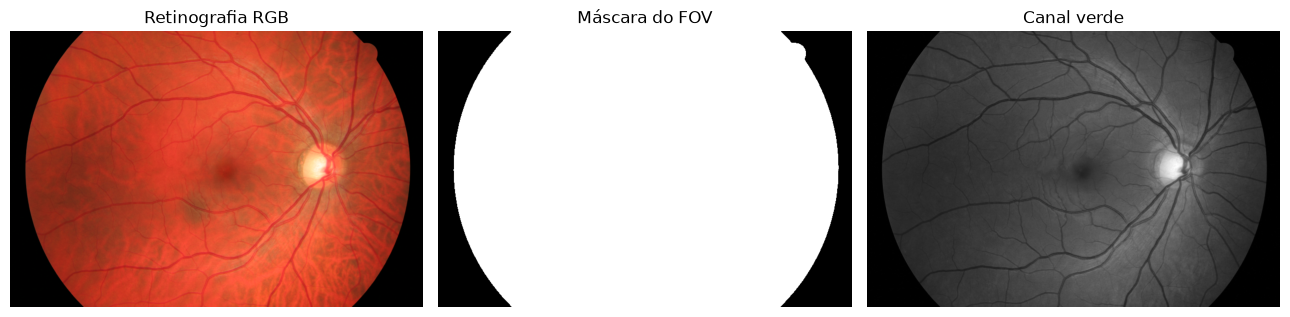

In [19]:
fig, axs = plt.subplots(1, 3, figsize=(13, 4.5))
for ax, im, titulo, cm in zip(
    axs,
    [rgb, fov, rgb[..., 1]],
    ["Retinografia RGB", "Máscara do FOV", "Canal verde"],
    [None, "gray", "gray"],
):
    ax.imshow(im, cmap=cm)
    ax.set_title(titulo)
    ax.axis("off")
fig.tight_layout()
plt.show()

## 2. Exercício de filtragem

Os dois defeitos são criados artificialmente sobre a **mesma imagem**. Assim, a imagem antes do ruído é conhecida e pode ser usada como referência para calcular o PSNR, que mede a diferença entre duas imagens. O filtro gaussiano tende a suavizar ruído contínuo. A mediana é adequada a pixels extremos, como ruído de sal e pimenta, mas pode apagar vasos muito finos.

Para evitar a influência da moldura preta, o código primeiro preenche a área exterior ao FOV com estimativas locais, conforme `P.preencher_fora_do_fov` do repositório. O PSNR só considera o interior da retina.

In [20]:
SEMENTE = 42
rng = np.random.default_rng(SEMENTE)
verde = P.preencher_fora_do_fov(rgb[..., 1], fov)
ruido_gaussiano = np.clip(verde.astype(np.float32) + rng.normal(0, 12, verde.shape), 0, 255).astype(np.uint8)
ruido_impulsivo = verde.copy()
u = rng.random(verde.shape)
ruido_impulsivo[u < 0.02] = 0
ruido_impulsivo[u > 0.98] = 255

filtros = {
    "Sem filtro": lambda x: x,
    "Gaussiano sigma 1": lambda x: cv2.GaussianBlur(x, (0, 0), 1.0),
    "Mediana 3x3": lambda x: cv2.medianBlur(x, 3),
    "Mediana 5x5": lambda x: cv2.medianBlur(x, 5),
}

def psnr_dentro_fov(referencia, estimativa, mascara):
    dif = referencia[mascara].astype(np.float32) - estimativa[mascara].astype(np.float32)
    mse = float(np.mean(dif ** 2))
    return float("inf") if mse == 0 else 10 * np.log10(255.0 ** 2 / mse)

res_filtragem = []
imagens_filtradas = {}
for tipo_ruido, entrada in [("Gaussiano", ruido_gaussiano), ("Sal e pimenta", ruido_impulsivo)]:
    for nome, aplicar in filtros.items():
        t0 = time.perf_counter()
        saida = aplicar(entrada)
        duracao_ms = (time.perf_counter() - t0) * 1000
        imagens_filtradas[(tipo_ruido, nome)] = saida
        res_filtragem.append({"Ruído": tipo_ruido, "Filtro": nome,
                              "PSNR (dB)": psnr_dentro_fov(verde, saida, fov),
                              "Tempo (ms)": duracao_ms})
tabela_filtros = pd.DataFrame(res_filtragem)
display(tabela_filtros.round(2))

,Ruído,Filtro,PSNR (dB),Tempo (ms)
0,Gaussiano,Sem filtro,26.54,0.00
1,Gaussiano,Gaussiano sigma 1,35.87,0.52
2,Gaussiano,Mediana 3x3,33.52,0.19
3,Gaussiano,Mediana 5x5,35.33,1.53
4,Sal e pimenta,Sem filtro,19.02,0.00
5,Sal e pimenta,Gaussiano sigma 1,29.31,0.76
6,Sal e pimenta,Mediana 3x3,42.72,0.14
7,Sal e pimenta,Mediana 5x5,39.48,1.84


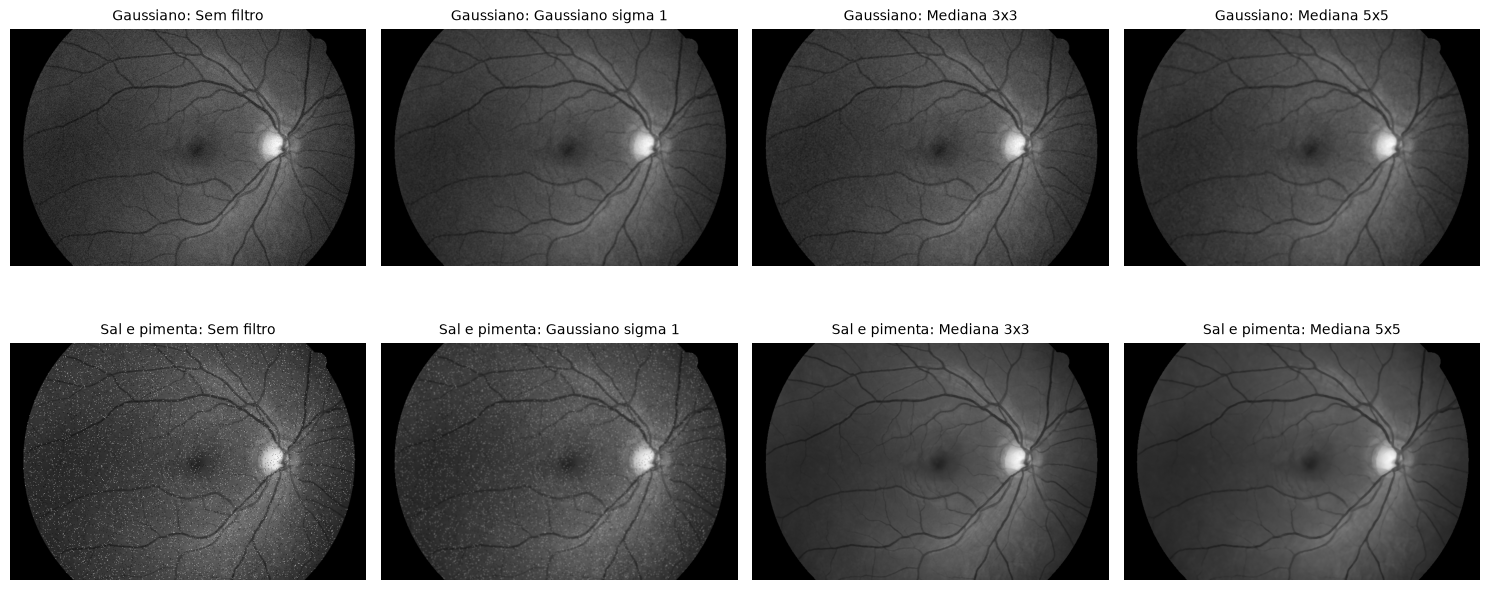

Maior PSNR para ruído gaussiano: Gaussiano sigma 1 (35.87 dB)
Maior PSNR para ruído sal e pimenta: Mediana 3x3 (42.72 dB)


In [21]:
fig, axs = plt.subplots(2, 4, figsize=(15, 7))
for i, tipo in enumerate(["Gaussiano", "Sal e pimenta"]):
    for j, nome in enumerate(filtros):
        im = imagens_filtradas[(tipo, nome)].copy()
        im[~fov] = 0
        axs[i, j].imshow(im, cmap="gray", vmin=0, vmax=255)
        axs[i, j].set_title(f"{tipo}: {nome}", fontsize=10)
        axs[i, j].axis("off")
fig.tight_layout()
plt.show()

for tipo, grupo in tabela_filtros.groupby("Ruído"):
    melhor = grupo.loc[grupo["PSNR (dB)"].idxmax()]
    print(f"Maior PSNR para ruído {tipo.lower()}: {melhor['Filtro']} ({melhor['PSNR (dB)']:.2f} dB)")

## 3. Exercício de CLAHE na luminância do LAB

O CLAHE equaliza blocos locais e limita a amplificação do contraste. Neste exercício o realce é aplicado apenas ao canal L do espaço LAB, com `clip=2.0` e `grade=(8,8)`, configuração inicial apresentada na leitura dirigida.

A ordem usada no pipeline é: preencher o exterior do FOV, suavizar levemente, aplicar CLAHE em L e restaurar a moldura preta. A equalização independente de R, G e B é mostrada apenas como comparação, porque pode alterar as cores da retina.

In [22]:
preenchida = np.stack([P.preencher_fora_do_fov(rgb[..., i], fov) for i in range(3)], axis=-1)
suavizada = cv2.GaussianBlur(preenchida, (0, 0), 0.9)

def realcar_clahe(entrada_suavizada, mascara, clip=2.0, grade=(8, 8)):
    saida = P.clahe_lab(entrada_suavizada, clip=clip, grade=grade).copy()
    saida[~mascara] = 0
    return saida

rgb_suave = suavizada.copy()
rgb_suave[~fov] = 0
rgb_clahe = realcar_clahe(suavizada, fov)
rgb_canais_separados = np.stack([P.clahe(suavizada[..., i], 2.0, (8, 8)) for i in range(3)], axis=-1)
rgb_canais_separados[~fov] = 0

def cor_delta_media(referencia, candidata, mascara):
    a = cv2.cvtColor(referencia, cv2.COLOR_RGB2LAB).astype(np.float32)
    b = cv2.cvtColor(candidata, cv2.COLOR_RGB2LAB).astype(np.float32)
    return float(np.hypot(a[..., 1] - b[..., 1], a[..., 2] - b[..., 2])[mascara].mean())

avaliacao_clahe = []
for nome, im in [("Original", rgb), ("Filtrada", rgb_suave), ("CLAHE em L", rgb_clahe), ("CLAHE em RGB", rgb_canais_separados)]:
    avaliacao_clahe.append({
        "Etapa": nome,
        "Desvio-padrão verde (FOV)": M.contraste_rms(im[..., 1], fov),
        "Alteração cromática média": cor_delta_media(rgb_suave, im, fov)
    })
display(pd.DataFrame(avaliacao_clahe).round(2))

,Etapa,Desvio-padrão verde (FOV),Alteração cromática média
0,Original,21.66,0.85
1,Filtrada,21.31,0.00
2,CLAHE em L,26.34,0.45
3,CLAHE em RGB,29.55,20.90


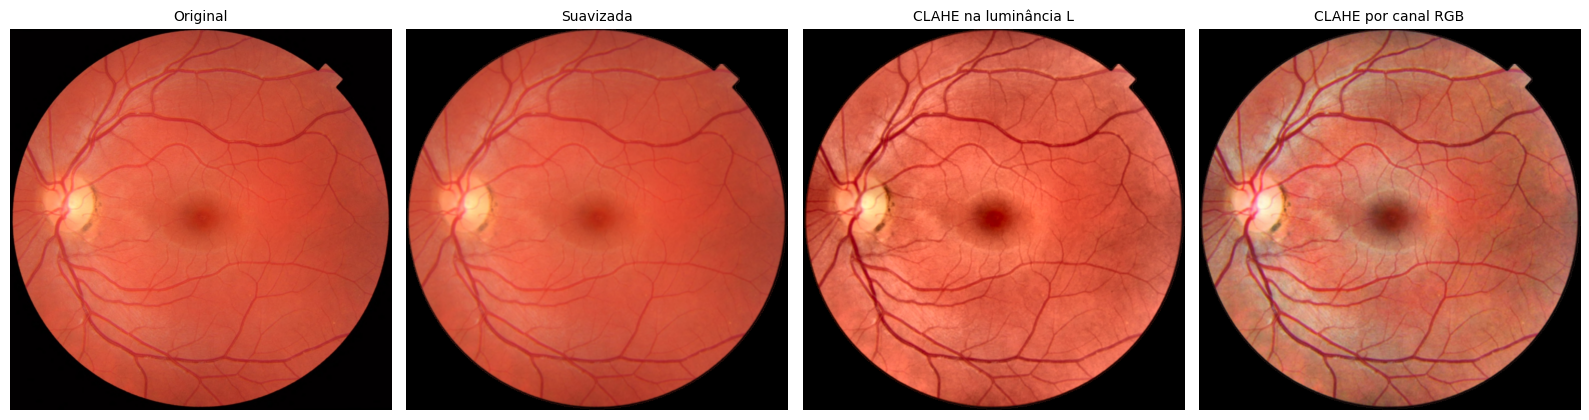

In [7]:
fig, axs = plt.subplots(1, 4, figsize=(16, 4.5))
for ax, (titulo, imagem) in zip(axs, [
    ("Original", rgb),
    ("Suavizada", rgb_suave),
    ("CLAHE na luminância L", rgb_clahe),
    ("CLAHE por canal RGB", rgb_canais_separados),
]):
    ax.imshow(imagem)
    ax.set_title(titulo, fontsize=10)
    ax.axis("off")
fig.tight_layout()
plt.show()

## 4. Exercício de segmentação de vasos

**Frangi:** detecta estruturas alongadas em várias escalas. O pacote `retina_pdi.pipeline` inclui preenchimento do FOV, correção de iluminação, Frangi, histerese e remoção de pequenos componentes. As escalas são medidas em pixels e são ajustadas à largura usada neste notebook.

**Black-hat:** subtrai o canal verde do seu fechamento morfológico, para evidenciar estruturas escuras menores que o elemento estruturante. A seleção por percentil e a limpeza dos componentes são uma comparação didática, e não um detector clínico validado.

O objetivo não é maximizar a fração de pixels marcados como vasos. Sem máscara manual, essa fração informa apenas quanto cada método selecionou, não sua qualidade.

In [23]:
FATOR_ESCALA = LARGURA / 1168
SIGMAS = tuple(float(x * FATOR_ESCALA) for x in (1.5, 2.5, 3.5))

def vasos_frangi(imagem, mascara):
    return P.segmentar_vasos(imagem, mascara, sigmas=SIGMAS)

def vasos_blackhat(imagem, mascara, diametro=17, percentil=89.0):
    canal = P.preencher_fora_do_fov(imagem[..., 1], mascara)
    eq = P.clahe(canal, 2.0, (8, 8))
    ee = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (diametro, diametro))
    resp = cv2.morphologyEx(eq, cv2.MORPH_BLACKHAT, ee)
    zona = P.erodir_fov(mascara, max(3, int(0.01 * min(mascara.shape))))
    limiar = np.percentile(resp[zona], percentil)
    b = (resp > limiar) & zona
    return P.remover_componentes_pequenos(b, max(1, int(3e-4 * b.size)))

inicio = time.perf_counter()
pred_frangi = vasos_frangi(rgb, fov)
tempo_frangi = (time.perf_counter() - inicio) * 1000
inicio = time.perf_counter()
pred_frangi_clahe = vasos_frangi(rgb_clahe, fov)
tempo_frangi_clahe = (time.perf_counter() - inicio) * 1000
inicio = time.perf_counter()
pred_blackhat = vasos_blackhat(rgb, fov)
tempo_blackhat = (time.perf_counter() - inicio) * 1000

segmentacoes = {
    "Frangi original": (pred_frangi, tempo_frangi),
    "Frangi após CLAHE": (pred_frangi_clahe, tempo_frangi_clahe),
    "Black-hat": (pred_blackhat, tempo_blackhat),
}
linhas_segmentacao = []
for nome, (pred, duracao_ms) in segmentacoes.items():
    item = {"Método": nome, "Área marcada no FOV (%)": 100 * pred[fov].mean(), "Tempo (ms)": duracao_ms}
    if gt_vasos is not None:
        item.update(P.metricas_segmentacao(pred, gt_vasos, fov))
    linhas_segmentacao.append(item)
tabela_segmentacao = pd.DataFrame(linhas_segmentacao)
display(tabela_segmentacao.round(3))

,Método,Área marcada no FOV (%),Tempo (ms),sensibilidade,especificidade,acuracia,precisao,dice,iou
0,Frangi original,9.006,2047.171,0.661,0.988,0.949,0.886,0.757,0.609
1,Frangi após CLAHE,8.656,914.207,0.636,0.989,0.946,0.887,0.741,0.588
2,Black-hat,9.762,86.016,0.669,0.981,0.943,0.827,0.740,0.587


NameError: name 'segmentacoes' is not defined

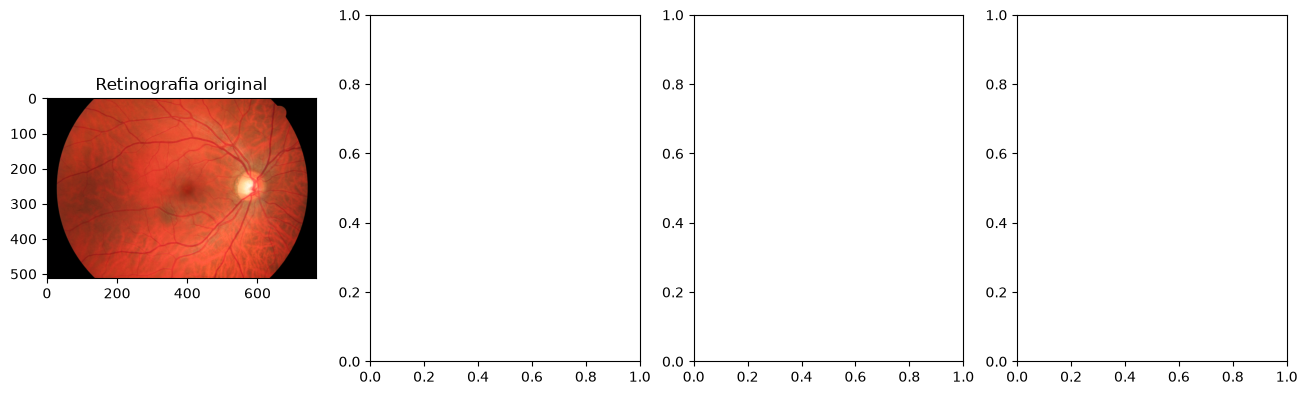

In [14]:
fig, axs = plt.subplots(1, 4, figsize=(16, 4.5))
axs[0].imshow(rgb)
axs[0].set_title("Retinografia original")
for ax, (titulo, (mascara, _)) in zip(axs[1:], segmentacoes.items()):
    sobreposicao = rgb.copy()
    sobreposicao[mascara] = (
        0.50 * sobreposicao[mascara].astype(np.float32) + 0.50 * np.array([0, 255, 0])
    ).astype(np.uint8)
    ax.imshow(sobreposicao)
    ax.set_title(titulo, fontsize=10)
for ax in axs:
    ax.axis("off")
fig.tight_layout()
plt.show()

## 5. Avaliação quantitativa e variação do CLAHE

O padrão-ouro para segmentar vasos é a máscara manual da base HRF. O pacote `P.metricas_segmentacao` compara cada pixel dentro do FOV e calcula, entre outros valores:

- **Dice:** `2 VP / (2 VP + FP + FN)`, proporção de sobreposição entre máscara prevista e máscara de referência.
- **IoU:** `VP / (VP + FP + FN)`, outra medida de sobreposição.
- **Sensibilidade:** parcela dos vasos presentes na referência que o algoritmo encontrou.
- **Precisão:** parcela dos pixels marcados pelo algoritmo que realmente corresponde a vasos.

A acurácia isolada é insuficiente, pois a maioria dos pixels do FOV é fundo. Sem a máscara oficial, não calcularemos Dice ou IoU. A seguir testamos uma grade pequena de parâmetros `clip` e `grade`; quando houver máscara HRF, o resultado pode ser ordenado por Dice. Caso contrário, apenas registramos contraste e área segmentada, sem escolher um vencedor por essas medidas.

In [15]:
import itertools
clips = [1.5, 2.0, 4.0]
# A última grade aproxima 64 pixels por bloco, como proposto no exercício 2 do notebook 03.
blocos_64 = (max(2, int(round(rgb.shape[1] / 64))), max(2, int(round(rgb.shape[0] / 64))))
grades = list(dict.fromkeys([(4, 4), (8, 8), blocos_64]))
resultado_grid = []
for clip, grade in itertools.product(clips, grades):
    x = realcar_clahe(suavizada, fov, clip=clip, grade=grade)
    pred = vasos_frangi(x, fov)
    linha = {"clip": clip, "grade": str(grade),
             "contraste verde": M.contraste_rms(x[..., 1], fov),
             "área prevista (%)": 100 * pred[fov].mean()}
    if gt_vasos is not None:
        linha["Dice"] = P.metricas_segmentacao(pred, gt_vasos, fov)["dice"]
    resultado_grid.append(linha)
tabela_grid = pd.DataFrame(resultado_grid)
if gt_vasos is not None:
    tabela_grid = tabela_grid.sort_values("Dice", ascending=False)
display(tabela_grid.round(3))

NameError: name 'vasos_frangi' is not defined

In [11]:
# Testes de coerência básicos: formatos, máscara, faixa numérica e definição de Dice.
assert rgb_clahe.shape == rgb.shape and rgb_clahe.dtype == np.uint8
assert not rgb_clahe[~fov].any(), "A moldura deve estar preta após o CLAHE"
for nome, (pred, _) in segmentacoes.items():
    assert pred.shape == fov.shape and pred.dtype == bool, nome
    assert not (pred & ~fov).any(), nome
mascara_teste = np.zeros((10, 10), dtype=bool)
mascara_teste[2:5, 2:5] = True
assert P.metricas_segmentacao(mascara_teste, mascara_teste)["dice"] == 1.0
assert P.metricas_segmentacao(~mascara_teste, mascara_teste)["dice"] == 0.0
print("Testes de coerência concluídos.")
if gt_vasos is None:
    print("Dice e IoU não calculados: a imagem de exemplo não dispõe de máscara manual de vasos.")
else:
    print("Máscara de referência HRF carregada. Dice e IoU constam da tabela de segmentação.")

Testes de coerência concluídos.
Dice e IoU não calculados: a imagem de exemplo não dispõe de máscara manual de vasos.


## 6. Discussão e limites

**Filtragem:** compare a tabela de PSNR obtida para ruído gaussiano e sal e pimenta. Um filtro pode aumentar o PSNR e ainda eliminar estruturas retinianas finas. Portanto, a escolha do filtro não deve depender apenas do aspecto visual.

**CLAHE:** o realce em L do LAB conserva melhor a informação cromática do que equalizar R, G e B de forma independente. O aumento do desvio-padrão mede contraste global, mas não comprova melhora na identificação de vasos ou de lesões. O CLAHE também pode amplificar ruído.

**Segmentação:** o Frangi utiliza a geometria alongada dos vasos; o black-hat depende da largura do elemento estruturante. Na base HRF, a comparação por Dice e IoU é mais adequada do que acurácia isolada. Não há razão para afirmar que aplicar CLAHE sempre melhora o Dice. Isso precisa ser medido.

**Limitações:** o desempenho muda com a resolução, a câmera, os parâmetros e a presença de lesões. A máscara manual do HRF é necessária para quantificar erros. As imagens do módulo têm rótulos herdados das bases e a atividade não estima desempenho clínico.

In [24]:
melhores_filtros = {}
for tipo, grupo in tabela_filtros.groupby("Ruído"):
    row = grupo.loc[grupo["PSNR (dB)"].idxmax()]
    melhores_filtros[tipo] = f"{row['Filtro']} ({row['PSNR (dB)']:.2f} dB)"

if gt_vasos is None:
    avaliacao_texto = (
        "Usei uma retinografia de exemplo do scikit-image porque o ZIP do repositório não "
        "contém as máscaras de referência HRF. Por isso, não calculei Dice nem IoU nesta execução. "
        "Essas métricas serão calculadas após obter as máscaras oficiais."
    )
else:
    linha = tabela_segmentacao.loc[tabela_segmentacao["dice"].idxmax()]
    avaliacao_texto = (
        f"Na imagem HRF analisada, o maior Dice foi {linha['dice']:.3f} e o IoU foi "
        f"{linha['iou']:.3f}, obtidos com {linha['Método']}. "
        "O resultado se refere a esta imagem, não às 45 imagens da base."
    )

texto_avea = (
    "Exercícios de programação, filtragem, CLAHE e segmentação\n\n"
    "Implementei o pipeline de processamento de retinografias usando o código do módulo 02. "
    "Primeiro isolei o FOV e comparei filtros após adicionar ruídos conhecidos. "
    f"O melhor PSNR com ruído gaussiano foi {melhores_filtros['Gaussiano']}; "
    f"com sal e pimenta foi {melhores_filtros['Sal e pimenta']}. "
    "Depois apliquei CLAHE no canal L do LAB, com preenchimento do exterior do FOV e suavização anterior, "
    "e comparei Frangi com black-hat para segmentar vasos. "
    + avaliacao_texto + "\n\n"
    "Anexo o notebook com código, tabelas, imagens e limitações. "
    "Solicito feedback sobre os parâmetros, a ordem dos filtros e a avaliação da segmentação."
)
print(texto_avea)

Exercícios de programação, filtragem, CLAHE e segmentação

Implementei o pipeline de processamento de retinografias usando o código do módulo 02. Primeiro isolei o FOV e comparei filtros após adicionar ruídos conhecidos. O melhor PSNR com ruído gaussiano foi Gaussiano sigma 1 (35.87 dB); com sal e pimenta foi Mediana 3x3 (42.72 dB). Depois apliquei CLAHE no canal L do LAB, com preenchimento do exterior do FOV e suavização anterior, e comparei Frangi com black-hat para segmentar vasos. Na imagem HRF analisada, o maior Dice foi 0.757 e o IoU foi 0.609, obtidos com Frangi original. O resultado se refere a esta imagem, não às 45 imagens da base.

Anexo o notebook com código, tabelas, imagens e limitações. Solicito feedback sobre os parâmetros, a ordem dos filtros e a avaliação da segmentação.
